In [1]:
import numpy as np
from numpy import sqrt, zeros, ones, pi, linspace, sin, cos, tan, atan, exp 
import matplotlib.pyplot as plt
hbar_c = 200 # hbar*c in nm*eV

### In this notebook, we wish to calculate the "effective" permittivity, $\varepsilon_\text{eff}$, of an interface between a metal (described with a nonlocal response function) and vacuum (in particular, we wish to recreate **Figure 1** of [Role of diffusive surface scattering in nonlocal plasmonics](https://iopscience.iop.org/article/10.1088/1361-648X/ab977d/pdf). To do so, we note that the effective permittivity is given by $\mathbf{D}(\mathbf{r}, \omega)=\varepsilon_0\varepsilon_\text{eff}(\mathbf{r}, \omega)\mathbf{E}(\mathbf{r}, \omega) \rightarrow \mathbf{P}(\mathbf{r}, \omega)=\varepsilon_0(\varepsilon_\text{eff}(\mathbf{r}, \omega)-1)\mathbf{E}(\mathbf{r}, \omega)$. We may equivalently write this in terms of a current-field relation: $\mathbf{J}(\mathbf{r}, \omega)=-i\omega\varepsilon_0(\varepsilon_\text{eff}(\mathbf{r}, \omega)-1)\mathbf{E}(\mathbf{r},\omega)$

### From this, we obtain the following: 

### $\begin{align*}\varepsilon_\text{eff}(\mathbf{r}, \omega)=\varepsilon_m +\frac{\beta_F^2}{\omega(\omega+i\gamma)}\frac{\nabla(\nabla\cdot\mathbf{E}(\mathbf{r}, \omega))}{E_z(\mathbf{r}, \omega)}\end{align*}$

### $\begin{align*}\varepsilon_\text{eff}=\varepsilon_m+\frac{\beta_F^2}{\omega(\omega+i\gamma)}\frac{\alpha k^2_{nl} q_{nl}}{-\alpha q_{nl}+ k_\tau \exp(i(q_{nl}-q_2)z)}=\varepsilon_m\Bigg[1+\frac{\alpha q_{nl}}{-\alpha q_{nl}+k_\tau \exp(i(q_{nl}-q_2)z)}\Bigg]\end{align*}$

### We first find the field field coefficients. 

In [30]:
def alpha_p_diffusive(omega, gamma, v_F, theta, d_prefac=6.64e-3): 
    epsilon = 1 - 1/(omega*(omega+1j*gamma))
    eta_sqrd = 3/5*v_F**2 + d_prefac*(v_F**2/gamma)*(gamma-1j*omega)
    k_nl_sqrd = (1/eta_sqrd)*(1+1j*gamma/omega-1/omega**2)
    kappa_nl = sqrt(k_nl_sqrd-sin(theta)**2)
    kappa_nl = np.where(kappa_nl.imag < 0, -kappa_nl, kappa_nl)

    return (1-epsilon)*sin(theta)/kappa_nl

In [45]:
def effective_epsilon(omega, theta, z, gamma = 5e-3, v_F=1.07/300, d_prefac=6.64e-3): # Fermi velocity in speed of light units
    # z is really z*omega/c
    epsilon = 1 - 1/(omega*(omega+1j*gamma)) # Drude dielectric function
    eta_sqrd = 3/5*v_F**2 + d_prefac*(v_F**2/gamma)*(gamma-1j*omega)
    k_nl_sqrd = (1/eta_sqrd)*(1+1j*gamma/omega-1/omega**2)
    kappa_nl = sqrt(k_nl_sqrd-sin(theta)**2)
    kappa_nl = np.where(kappa_nl.imag < 0, -kappa_nl, kappa_nl)

    q_2 = sqrt(epsilon-sin(theta)**2)
    q_2 = np.where(q_2.imag < 0, -q_2, q_2)

    alpha = alpha_p_diffusive(omega, gamma, v_F, theta, d_prefac=d_prefac)
    prefactor = alpha * kappa_nl/(-alpha*kappa_nl + sin(theta)*exp(1j*(kappa_nl-q_2)*z))
    effective_epsilon_arr = epsilon * (1 + prefactor)
    effective_epsilon_arr = np.where(z < 0, effective_epsilon_arr, 1)
    return effective_epsilon_arr

In [46]:
N_omegas = 1000
N_z = 1000
omegas = linspace(0.3, 0.8, N_omegas) # omega/omega_p
z_v = linspace(-1.5, 0.5, N_z)
hbar_omega_p = 5
z_arr = z_v.reshape((N_z, 1)).repeat(N_omegas, axis=1)
omegas_arr = omegas.reshape((1, N_omegas)).repeat(N_z, axis=0);

In [68]:
effective_permittivities = effective_epsilon(omegas_arr, pi/2, z_arr*omegas_arr*hbar_omega_p/hbar_c, gamma = 5e-3, v_F=1.07/300)

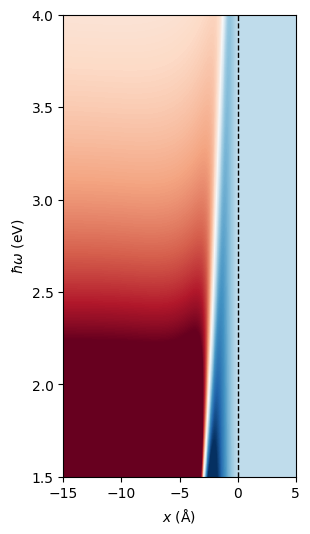

In [69]:
extent = [10*z_v[0], 10*z_v[-1],
          omegas[0]*hbar_omega_p, omegas[-1]*hbar_omega_p]

fig, ax = plt.subplots(figsize=(3, 6))
ax.imshow(effective_permittivities.real.T,
           cmap="RdBu", origin="lower", aspect="auto",
           extent=extent, vmin=-4, vmax=4,
           interpolation="nearest")
ax.axvline(0, color="k", linestyle="--", linewidth=1)
ax.set_xlabel(r"$x$ (Å)")
ax.set_ylabel(r"$\hbar\omega$ (eV)");

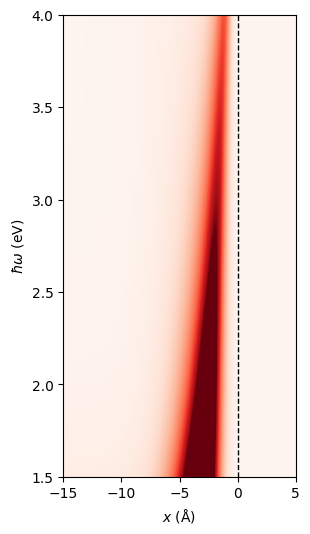

In [71]:
fig, ax = plt.subplots(figsize=(3, 6))

ax.imshow(effective_permittivities.imag.T,
           cmap="Reds", origin="lower", aspect="auto",
           extent=extent, vmin=0, vmax=4,
           interpolation="nearest")
ax.axvline(0, color="k", linestyle="--", linewidth=1)
ax.set_xlabel(r"$x$ (Å)")
ax.set_ylabel(r"$\hbar\omega$ (eV)");